# Case Final — Fraude no Varejo: o que as fraudes têm em comum?

**MBA FGV — Métodos e Ferramentas de Data Science** · Profa. Anna Carolina Barros
**Dupla:** Leandro Bittencourt e João Tonini

**Pergunta central:** o que os pedidos fraudulentos têm em comum, e o que os diferencia dos pedidos legítimos?
**KPI:** `fraude` (pedido confirmado como fraudulento após análise do chargeback — Sim/Não).
**Unidade de análise:** o pedido (uma linha = um pedido).

Metodologia **ACB-EDA**, Etapas 1 a 6 e 8 (a Etapa 7, multivariada, não faz parte deste case).
Todas as conclusões se apoiam em análises **univariadas e bivariadas**: identificam **associações**, não causas.

## 0. Configuração

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (9, 4.5)

URL = 'https://raw.githubusercontent.com/lleandrogb/mba-fgv-case-fraude/main/varejo_fraude_pedidos.csv'
df_bruto = pd.read_csv(URL, parse_dates=['data_hora_pedido'])
print(df_bruto.shape)
df_bruto.head()

(6025, 24)


,id_pedido,data_hora_pedido,canal_venda,categoria_principal,qtd_itens,valor_pedido,metodo_pagamento,num_parcelas,tentativas_pagamento,cartoes_cadastrados_30d,convidado,tempo_conta_dias,pedidos_anteriores,dominio_email,dispositivo_novo,contas_mesmo_dispositivo,ip_proxy_vpn,tempo_sessao_min,endereco_entrega_igual_cobranca,tipo_entrega,uf_entrega,cupom_utilizado,estorno_solicitado,fraude
0,PED100103,2025-07-08 18:47:12,App,Casa,3,407.87,Cartão de Crédito,12,1,1,Não,437.00,3,Gratuito,Sim,1,Não,14.10,Sim,Normal,MG,Sim,Não,Não
1,PED100257,2025-07-17 07:05:37,App,Beleza,3,280.84,Cartão Presente,1,1,0,Não,294.00,0,Gratuito,Não,1,Não,14.30,Sim,Normal,SP,Não,Não,Não
2,PED103299,2026-01-14 15:26:39,Site,Moda,1,294.36,Pix,1,2,0,Não,617.00,6,Gratuito,Não,1,Não,7.70,Sim,Normal,MG,Sim,Não,Não
3,PED103056,2026-01-01 20:07:59,Marketplace,Beleza,1,87.81,Cartão de Crédito,1,1,0,Não,307.00,1,Gratuito,Sim,2,Não,11.60,Sim,Retirada em Loja,DF,Sim,Não,Não
4,PED100696,2025-08-13 04:03:50,App,Moda,1,327.78,Cartão de Crédito,1,1,0,Não,281.00,6,Gratuito,Não,1,Não,8.50,Sim,Normal,PE,Não,Não,Não


### Funções auxiliares

Como a fraude é um evento **raro**, toda tabela bivariada mostra a **taxa junto com o volume** do grupo
(regra do enunciado: *"uma taxa alta num grupo com poucos pedidos pode ser ruído"*).
Grupos com menos de 30 pedidos são sinalizados.

In [2]:
MIN_N = 30  # abaixo disso, a taxa do grupo é instável

def tabela_taxa(d, var, kpi='fraude_bin'):
    """Taxa de fraude por grupo, com volume e participação no total de pedidos e de fraudes."""
    t = d.groupby(var, observed=True)[kpi].agg(pedidos='size', fraudes='sum')
    taxa_geral = d[kpi].mean()
    t['taxa_fraude_%'] = 100 * t['fraudes'] / t['pedidos']
    t['part_pedidos_%'] = 100 * t['pedidos'] / t['pedidos'].sum()
    t['part_fraudes_%'] = 100 * t['fraudes'] / t['fraudes'].sum()
    t['razao_vs_geral'] = (t['fraudes'] / t['pedidos']) / taxa_geral
    t['n_pequeno'] = np.where(t['pedidos'] < MIN_N, '⚠️', '')
    return t

def grafico_taxa(d, var, titulo, kpi='fraude_bin', ax=None, rot=0):
    """Barras com a taxa de fraude por grupo; o n de cada grupo aparece sobre a barra."""
    t = tabela_taxa(d, var, kpi)
    if ax is None:
        _, ax = plt.subplots()
    cores = ['#bbbbbb' if n < MIN_N else '#c0392b' for n in t['pedidos']]
    ax.bar(t.index.astype(str), t['taxa_fraude_%'], color=cores)
    ax.axhline(100 * d[kpi].mean(), ls='--', color='black', lw=1, label=f'taxa geral ({100*d[kpi].mean():.1f}%)')
    for i, (taxa, n) in enumerate(zip(t['taxa_fraude_%'], t['pedidos'])):
        ax.text(i, taxa, f'{taxa:.1f}%\nn={n}', ha='center', va='bottom', fontsize=8)
    ax.set_title(titulo)
    ax.set_xlabel(var)
    ax.set_ylabel('Taxa de fraude (%)')
    ax.set_ylim(0, max(t['taxa_fraude_%'].max() * 1.25, 10))
    ax.tick_params(axis='x', rotation=rot)
    ax.legend(loc='upper left', fontsize=8)
    return t

## Etapa 1 — Alinhamento e escopo

O enunciado traz as explicações de cada área. Elas são o ponto de partida das hipóteses
(o fraudador precisa **comprar algo revendável, pagar, receber a mercadoria e não ser identificado**).

| # | Hipótese (origem) | Variáveis da base | Conhecida quando? |
|---|---|---|---|
| H1 | Fraude concentra-se em pedidos de **alto valor** e produtos de **fácil revenda** (Prevenção a Perdas) | `valor_pedido`, `categoria_principal`, `qtd_itens` | No pedido |
| H2 | O **cartão de crédito** e sinais de **teste de cartão** estão associados à fraude (Pagamentos) | `metodo_pagamento`, `tentativas_pagamento`, `cartoes_cadastrados_30d` | No pedido |
| H3 | **Retirada em loja** e **entrega expressa** facilitam a fraude; entrega fora do endereço do titular também (Logística) | `tipo_entrega`, `endereco_entrega_igual_cobranca` | No pedido |
| H4 | **Contas recém-criadas** e **compras como convidado** concentram fraude (Produto) | `tempo_conta_dias`, `convidado`, `pedidos_anteriores`, `dominio_email` | No pedido |
| H5 | Há **ação organizada** (quadrilhas): vários perfis no mesmo aparelho, rede mascarada | `contas_mesmo_dispositivo`, `dispositivo_novo`, `ip_proxy_vpn` | No pedido |
| H6 | O **comportamento na sessão** e o **horário** diferem (compra rápida, madrugada) | `tempo_sessao_min`, `hora` (derivada de `data_hora_pedido`) | No pedido |

**Variáveis fora da análise:**

| Variável | Motivo |
|---|---|
| `estorno_solicitado` | Só é conhecida **depois** do pedido e faz parte do próprio processo que gera o rótulo (contestação → chargeback → fraude). Usá-la como explicativa seria circular. |
| `id_pedido` | Identificador; usado só no sanity check de duplicidade. |
| `canal_venda`, `uf_entrega`, `cupom_utilizado`, `num_parcelas` | Sem hipótese de negócio associada no enunciado (`num_parcelas` é redundante com o método de pagamento). Ver Etapa 6, quadro de controle. |

**Limite de mensuração:** não existe coluna que diga se um pedido foi feito por quadrilha.
`contas_mesmo_dispositivo` é uma **proxy** de ação organizada, não a medida direta.

> ✍️ **Hipóteses e justificativa das variáveis** — *texto do Leandro*
>
> - Concorda com as seis hipóteses? Quer cortar, juntar ou acrescentar alguma? (o mínimo exigido são quatro)
> - Por que cada variável representa a hipótese — e onde ela é só uma proxy?
> - Justificar as exclusões (o case pede justificativa da exclusão também).
>
> _[escrever aqui]_

## Etapa 2 — Sanity check do KPI central (`fraude`)

Verificações: existência e tipo, ausentes, categorias, consistência, granularidade/duplicidade
e **momento de definição do rótulo**.

In [3]:
print('Coluna existe?', 'fraude' in df_bruto.columns)
print('Tipo:', df_bruto['fraude'].dtype)
print('Ausentes:', df_bruto['fraude'].isna().sum())
df_bruto['fraude'].value_counts(dropna=False)

Coluna existe? True
Tipo: str
Ausentes: 0


fraude
Não    5683
Sim     330
sim       6
S         5
nao       1
Name: count, dtype: int64

**Achado:** além de `Sim` e `Não`, aparecem grafias inconsistentes (`S`, `sim`, `nao`).
Todas têm interpretação inequívoca, então são **padronizadas**, não descartadas.

In [4]:
df = df_bruto.copy()
mapa_kpi = {'sim': 'Sim', 's': 'Sim', 'não': 'Não', 'nao': 'Não'}
df['fraude'] = df['fraude'].str.strip().str.lower().map(mapa_kpi)
print('Valores sem mapeamento:', df['fraude'].isna().sum())
df['fraude_bin'] = (df['fraude'] == 'Sim').astype(int)
df['fraude'].value_counts()

Valores sem mapeamento: 0


fraude
Não    5684
Sim     341
Name: count, dtype: int64

### Granularidade e duplicidade

In [5]:
print('Linhas:', len(df))
print('IDs repetidos:', df['id_pedido'].duplicated().sum())
print('Linhas inteiramente repetidas:', df_bruto.duplicated().sum())

# os IDs repetidos são cópias idênticas da linha inteira?
ids_rep = df.loc[df['id_pedido'].duplicated(keep=False), 'id_pedido']
print('Pedidos envolvidos:', ids_rep.nunique())
df_bruto[df_bruto['id_pedido'].isin(ids_rep)].sort_values('id_pedido').head(6)

Linhas: 6025
IDs repetidos: 25
Linhas inteiramente repetidas: 25
Pedidos envolvidos: 25


,id_pedido,data_hora_pedido,canal_venda,categoria_principal,qtd_itens,valor_pedido,metodo_pagamento,num_parcelas,tentativas_pagamento,cartoes_cadastrados_30d,convidado,tempo_conta_dias,pedidos_anteriores,dominio_email,dispositivo_novo,contas_mesmo_dispositivo,ip_proxy_vpn,tempo_sessao_min,endereco_entrega_igual_cobranca,tipo_entrega,uf_entrega,cupom_utilizado,estorno_solicitado,fraude
5203,PED100234,2025-07-16 22:48:58,App,Casa,5,507.67,Cartão de Crédito,3,1,1,Sim,NaN,0,Gratuito,Não,1,Não,10.80,Sim,Expressa,RJ,Não,Não,Não
3220,PED100234,2025-07-16 22:48:58,App,Casa,5,507.67,Cartão de Crédito,3,1,1,Sim,NaN,0,Gratuito,Não,1,Não,10.80,Sim,Expressa,RJ,Não,Não,Não
588,PED100250,2025-07-17 11:21:17,App,Casa,3,680.93,Cartão de Crédito,5,1,1,Não,355.00,2,Gratuito,Não,1,Não,11.80,Sim,Normal,BA,Não,Não,Não
2363,PED100250,2025-07-17 11:21:17,App,Casa,3,680.93,Cartão de Crédito,5,1,1,Não,355.00,2,Gratuito,Não,1,Não,11.80,Sim,Normal,BA,Não,Não,Não
5986,PED100276,2025-07-19 12:36:19,App,Celulares,2,"1,722.65",Pix,1,1,2,Não,69.00,0,Gratuito,Não,1,Não,14.70,Sim,Normal,RJ,Não,Não,Não
5558,PED100276,2025-07-19 12:36:19,App,Celulares,2,"1,722.65",Pix,1,1,2,Não,69.00,0,Gratuito,Não,1,Não,14.70,Sim,Normal,RJ,Não,Não,Não


In [6]:
df = df.drop_duplicates(subset='id_pedido', keep='first').reset_index(drop=True)
print('Após remover duplicatas:', len(df), 'pedidos | IDs únicos:', df['id_pedido'].is_unique)

Após remover duplicatas: 6000 pedidos | IDs únicos: True


### Momento de definição do rótulo (maturação)

A fraude é confirmada **até 90 dias** depois do pedido. Pedidos dos últimos 90 dias da base
ainda podem ter contestações em andamento: tiveram **menos chance** de ser rotulados como fraude.

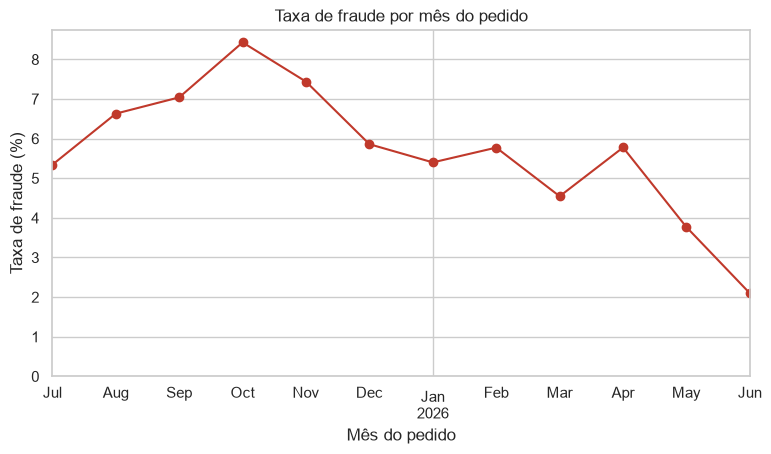

,pedidos,fraudes,taxa_%
data_hora_pedido,,,
2025-07,468,25,5.34
2025-08,558,37,6.63
2025-09,497,35,7.04
2025-10,522,44,8.43
2025-11,484,36,7.44
2025-12,512,30,5.86
2026-01,537,29,5.40
2026-02,433,25,5.77
2026-03,484,22,4.55


In [7]:
mensal = df.groupby(df['data_hora_pedido'].dt.to_period('M'))['fraude_bin'].agg(pedidos='size', fraudes='sum')
mensal['taxa_%'] = 100 * mensal['fraudes'] / mensal['pedidos']

ax = mensal['taxa_%'].plot(marker='o', color='#c0392b')
ax.set_title('Taxa de fraude por mês do pedido')
ax.set_xlabel('Mês do pedido'); ax.set_ylabel('Taxa de fraude (%)')
ax.set_ylim(0, None)
plt.show()
mensal

In [8]:
# Premissa: a base foi extraída logo após o último pedido registrado.
DATA_REFERENCIA = df['data_hora_pedido'].max().normalize()
CORTE_MATURACAO = DATA_REFERENCIA - pd.Timedelta(days=90)
df['safra_madura'] = df['data_hora_pedido'] <= CORTE_MATURACAO

print('Data de referência:', DATA_REFERENCIA.date(), '| corte de maturação:', CORTE_MATURACAO.date())
df.groupby('safra_madura')['fraude_bin'].agg(pedidos='size', fraudes='sum', taxa='mean')

Data de referência: 2026-06-30 | corte de maturação: 2026-04-01


,pedidos,fraudes,taxa
safra_madura,,,
False,1505,58,0.04
True,4495,283,0.06


**Tratamento adotado:** a análise principal (Etapas 3 a 6) usa só a **safra madura** — pedidos com pelo
menos 90 dias até a data de referência —, para que todos os pedidos analisados tenham tido a mesma
chance de ser confirmados como fraude. Para usar a base inteira, basta trocar a chave abaixo.

In [9]:
USAR_SO_SAFRA_MADURA = True

base = df[df['safra_madura']].copy() if USAR_SO_SAFRA_MADURA else df.copy()
print(f'Base de análise: {len(base)} pedidos, {base.fraude_bin.sum()} fraudes')

Base de análise: 4495 pedidos, 283 fraudes


> ✍️ **O KPI está adequado à investigação?** — *texto do Leandro*
>
> - Quais tratamentos foram aplicados (padronização, duplicatas) e por quê?
> - Todos os pedidos tiveram a mesma chance de ser rotulados? O que o gráfico mensal mostra em maio e junho?
> - O que o KPI **não** diz? (ex.: fraude não contestada nunca vira 'Sim'; a premissa da data de extração)
>
> _[escrever aqui]_

## Etapa 3 — Análise univariada do KPI

In [10]:
freq = pd.DataFrame({
    'frequencia_absoluta': base['fraude'].value_counts(),
    'frequencia_relativa_%': 100 * base['fraude'].value_counts(normalize=True),
})
freq

,frequencia_absoluta,frequencia_relativa_%
fraude,,
Não,4212,93.70
Sim,283,6.30


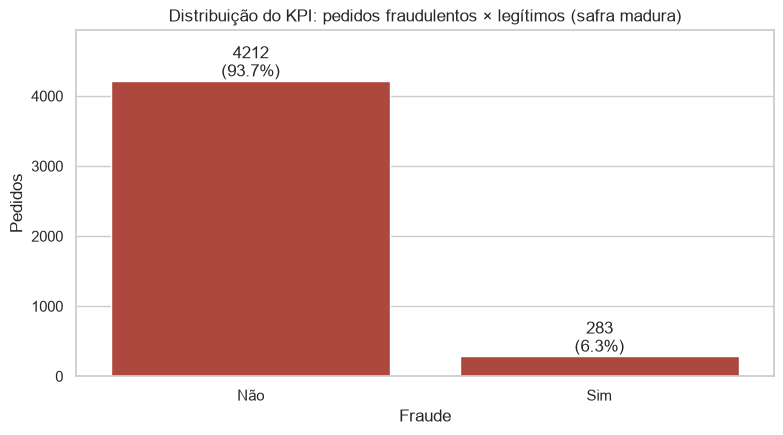

Proporção de pedidos fraudulentos: 6.30%
Baseline: classificar todo pedido como "Não" acertaria 93.7% — e não identificaria nenhuma fraude.


In [11]:
ax = sns.countplot(data=base, x='fraude', order=['Não', 'Sim'], color='#c0392b')
for p, pct in zip(ax.patches, freq.loc[['Não', 'Sim'], 'frequencia_relativa_%']):
    ax.annotate(f'{int(p.get_height())}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
ax.set_title('Distribuição do KPI: pedidos fraudulentos × legítimos (safra madura)')
ax.set_xlabel('Fraude'); ax.set_ylabel('Pedidos')
ax.set_ylim(0, base.shape[0] * 1.1)
plt.show()

taxa = base['fraude_bin'].mean()
print(f'Proporção de pedidos fraudulentos: {100*taxa:.2f}%')
print(f'Baseline: classificar todo pedido como "Não" acertaria {100*(1-taxa):.1f}% — e não identificaria nenhuma fraude.')

> ✍️ **Interpretação da distribuição** — *texto do Leandro*
>
> - Qual é a proporção de fraude e o que ela implica para as próximas etapas?
> - Por que acurácia sozinha não basta, e por que é preciso olhar taxa junto com volume nos grupos?
>
> _[escrever aqui]_

## Etapa 4 — Sanity check das variáveis explicativas

Feito na base **completa** (`df`), porque problemas de qualidade não dependem da maturação do rótulo.
Os tratamentos são aplicados no fim e propagados para a `base` de análise.

In [12]:
explicativas = ['valor_pedido', 'categoria_principal', 'qtd_itens',
                'metodo_pagamento', 'tentativas_pagamento', 'cartoes_cadastrados_30d',
                'tipo_entrega', 'endereco_entrega_igual_cobranca',
                'tempo_conta_dias', 'convidado', 'pedidos_anteriores', 'dominio_email',
                'contas_mesmo_dispositivo', 'dispositivo_novo', 'ip_proxy_vpn',
                'tempo_sessao_min', 'data_hora_pedido']

qualidade = pd.DataFrame({
    'tipo': df[explicativas].dtypes.astype(str),
    'ausentes': df[explicativas].isna().sum(),
    'ausentes_%': 100 * df[explicativas].isna().mean(),
    'valores_distintos': df[explicativas].nunique(),
})
qualidade

,tipo,ausentes,ausentes_%,valores_distintos
valor_pedido,float64,0,0.00,5851
categoria_principal,str,0,0.00,7
qtd_itens,int64,0,0.00,8
metodo_pagamento,str,0,0.00,4
tentativas_pagamento,int64,0,0.00,4
cartoes_cadastrados_30d,int64,0,0.00,5
tipo_entrega,str,0,0.00,3
endereco_entrega_igual_cobranca,str,0,0.00,2
tempo_conta_dias,float64,929,15.48,1430
convidado,str,0,0.00,2


### Categorias presentes

In [13]:
categoricas = ['categoria_principal', 'metodo_pagamento', 'tipo_entrega', 'endereco_entrega_igual_cobranca',
               'convidado', 'dominio_email', 'dispositivo_novo', 'ip_proxy_vpn']
for c in categoricas + ['uf_entrega']:
    print(f'{c}: {df[c].value_counts(dropna=False).to_dict()}')

categoria_principal: {'Moda': 1299, 'Casa': 1062, 'Beleza': 951, 'Mercado': 865, 'Eletrônicos': 809, 'Celulares': 608, 'Games': 406}
metodo_pagamento: {'Cartão de Crédito': 3267, 'Pix': 1923, 'Boleto': 476, 'Cartão Presente': 334}
tipo_entrega: {'Normal': 3875, 'Expressa': 1191, 'Retirada em Loja': 934}
endereco_entrega_igual_cobranca: {'Sim': 4774, 'Não': 1226}
convidado: {'Não': 5071, 'Sim': 929}
dominio_email: {'Gratuito': 5025, 'Corporativo': 796, 'Temporário': 179}
dispositivo_novo: {'Não': 4779, 'Sim': 1221}
ip_proxy_vpn: {'Não': 5675, 'Sim': 325}
uf_entrega: {'SP': 1936, 'RJ': 803, 'MG': 656, 'PR': 427, 'RS': 385, 'BA': 348, 'SC': 331, 'PE': 321, 'CE': 249, 'DF': 246, 'GO': 231, 'São Paulo': 47, 'sp': 7, 'rj': 5, 'pr': 2, 'mg': 2, 'rs': 2, 'sc': 1, 'go': 1}


### Intervalos plausíveis

In [14]:
numericas = ['valor_pedido', 'qtd_itens', 'tentativas_pagamento', 'cartoes_cadastrados_30d',
             'tempo_conta_dias', 'pedidos_anteriores', 'contas_mesmo_dispositivo', 'tempo_sessao_min']
df[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
valor_pedido,"6,000.00","1,028.90","1,434.07","-2,156.76",202.16,385.67,"1,234.41","13,425.91"
qtd_itens,"6,000.00",2.29,1.15,1.00,1.00,2.00,3.00,8.00
tentativas_pagamento,"6,000.00",1.15,0.39,1.00,1.00,1.00,1.00,5.00
cartoes_cadastrados_30d,"6,000.00",0.30,0.54,0.00,0.00,0.00,1.00,4.00
tempo_conta_dias,"5,071.00",486.04,498.54,0.00,132.00,335.00,676.00,"5,578.00"
pedidos_anteriores,"6,000.00",3.41,4.43,0.00,0.00,2.00,5.00,36.00
contas_mesmo_dispositivo,"6,000.00",1.17,0.69,1.00,1.00,1.00,1.00,8.00
tempo_sessao_min,"5,992.00",12.90,8.32,1.10,7.20,10.80,16.30,90.70


In [15]:
print('Valor do pedido ≤ 0:', (df['valor_pedido'] <= 0).sum())
display(df.loc[df['valor_pedido'] <= 0, ['id_pedido', 'valor_pedido', 'categoria_principal', 'fraude']])

print('Contas com mais de 10 anos:', (df['tempo_conta_dias'] > 3650).sum(),
      '| maior valor:', df['tempo_conta_dias'].max(), 'dias')

Valor do pedido ≤ 0: 9


,id_pedido,valor_pedido,categoria_principal,fraude
105,PED102261,0.00,Beleza,Não
803,PED102687,0.00,Moda,Não
1639,PED105030,"-2,156.76",Eletrônicos,Não
1974,PED102871,0.00,Celulares,Não
2051,PED105626,-128.87,Moda,Não
2292,PED105535,0.00,Eletrônicos,Não
2926,PED100997,0.00,Casa,Não
3833,PED105035,-405.37,Casa,Não
5472,PED101245,0.00,Casa,Não


Contas com mais de 10 anos: 6 | maior valor: 5578.0 dias


### Ausentes com significado de negócio e coerência entre colunas

In [16]:
# tempo_conta_dias ausente ⇔ compra como convidado?
print(pd.crosstab(df['convidado'], df['tempo_conta_dias'].isna().rename('tempo_conta_ausente')))

# convidado não tem conta, mas aparece com pedidos anteriores?
incoerentes = (df['convidado'] == 'Sim') & (df['pedidos_anteriores'] > 0)
print('\nConvidados com pedidos_anteriores > 0:', incoerentes.sum())

# parcelamento só faz sentido no cartão de crédito
print('\nMétodo de pagamento dos pedidos com mais de 1 parcela:')
print(df.loc[df['num_parcelas'] > 1, 'metodo_pagamento'].value_counts())

# tempo de sessão ausente
print('\nTempo de sessão ausente:', df['tempo_sessao_min'].isna().sum(),
      '| fraudes entre eles:', df.loc[df['tempo_sessao_min'].isna(), 'fraude_bin'].sum())

tempo_conta_ausente  False  True 
convidado                        
Não                   5071      0
Sim                      0    929

Convidados com pedidos_anteriores > 0: 27

Método de pagamento dos pedidos com mais de 1 parcela:
metodo_pagamento
Cartão de Crédito    2100
Name: count, dtype: int64

Tempo de sessão ausente: 8 | fraudes entre eles: 0


### Tratamentos aplicados

| Problema | Tratamento | Por quê |
|---|---|---|
| `uf_entrega` com grafias diferentes (`São Paulo`, `sp`, `rj`…) | Padronizar para a sigla em maiúscula | Mesma UF contada como grupos distintos |
| `valor_pedido` ≤ 0 | Tornar ausente (`NaN`) só em `valor_pedido` | Valor impossível para um pedido; o resto da linha é aproveitável |
| `tempo_conta_dias` ausente | **Manter** ausente; tratar convidado como grupo próprio nas faixas | A ausência **é informação**: coincide exatamente com compra como convidado |
| Convidado com `pedidos_anteriores` > 0 | Sinalizar (`flag_incoerente`), não excluir | Pode ser histórico do e-mail/CPF; não há como confirmar |
| `tempo_sessao_min` ausente (poucos casos) | Manter ausente; fica fora só das análises dessa variável | Volume desprezível |
| Contas com mais de 10 anos | Manter, registrar como limitação | Plausível se a empresa for antiga; o dicionário não informa a data de fundação |

In [17]:
def tratar(d):
    d = d.copy()
    d['uf_entrega'] = d['uf_entrega'].replace({'São Paulo': 'SP'}).str.strip().str.upper()
    d.loc[d['valor_pedido'] <= 0, 'valor_pedido'] = np.nan
    d['flag_incoerente'] = (d['convidado'] == 'Sim') & (d['pedidos_anteriores'] > 0)
    d['hora'] = d['data_hora_pedido'].dt.hour
    return d

df = tratar(df)
base = tratar(base)
print(df['uf_entrega'].value_counts().to_dict())
print('valor_pedido ausente após tratamento:', df['valor_pedido'].isna().sum())

{'SP': 1990, 'RJ': 808, 'MG': 658, 'PR': 429, 'RS': 387, 'BA': 348, 'SC': 332, 'PE': 321, 'CE': 249, 'DF': 246, 'GO': 232}
valor_pedido ausente após tratamento: 9


> ✍️ **Limitações das variáveis e efeito na investigação** — *texto do Leandro*
>
> - Quais variáveis medem bem a hipótese e quais são só proxies? (ex.: `contas_mesmo_dispositivo` para quadrilha)
> - O que a ausência de `tempo_conta_dias` significa para o negócio?
> - Alguma variável pode estar disponível só depois do pedido? (`estorno_solicitado` já foi excluída)
>
> _[escrever aqui]_

## Etapa 5 — Análise univariada das variáveis explicativas

O tipo vem do **significado**, não do formato: contagens como `tentativas_pagamento` são numéricas
discretas; `categoria_principal` é nominal (não tem ordem).

### Variáveis categóricas

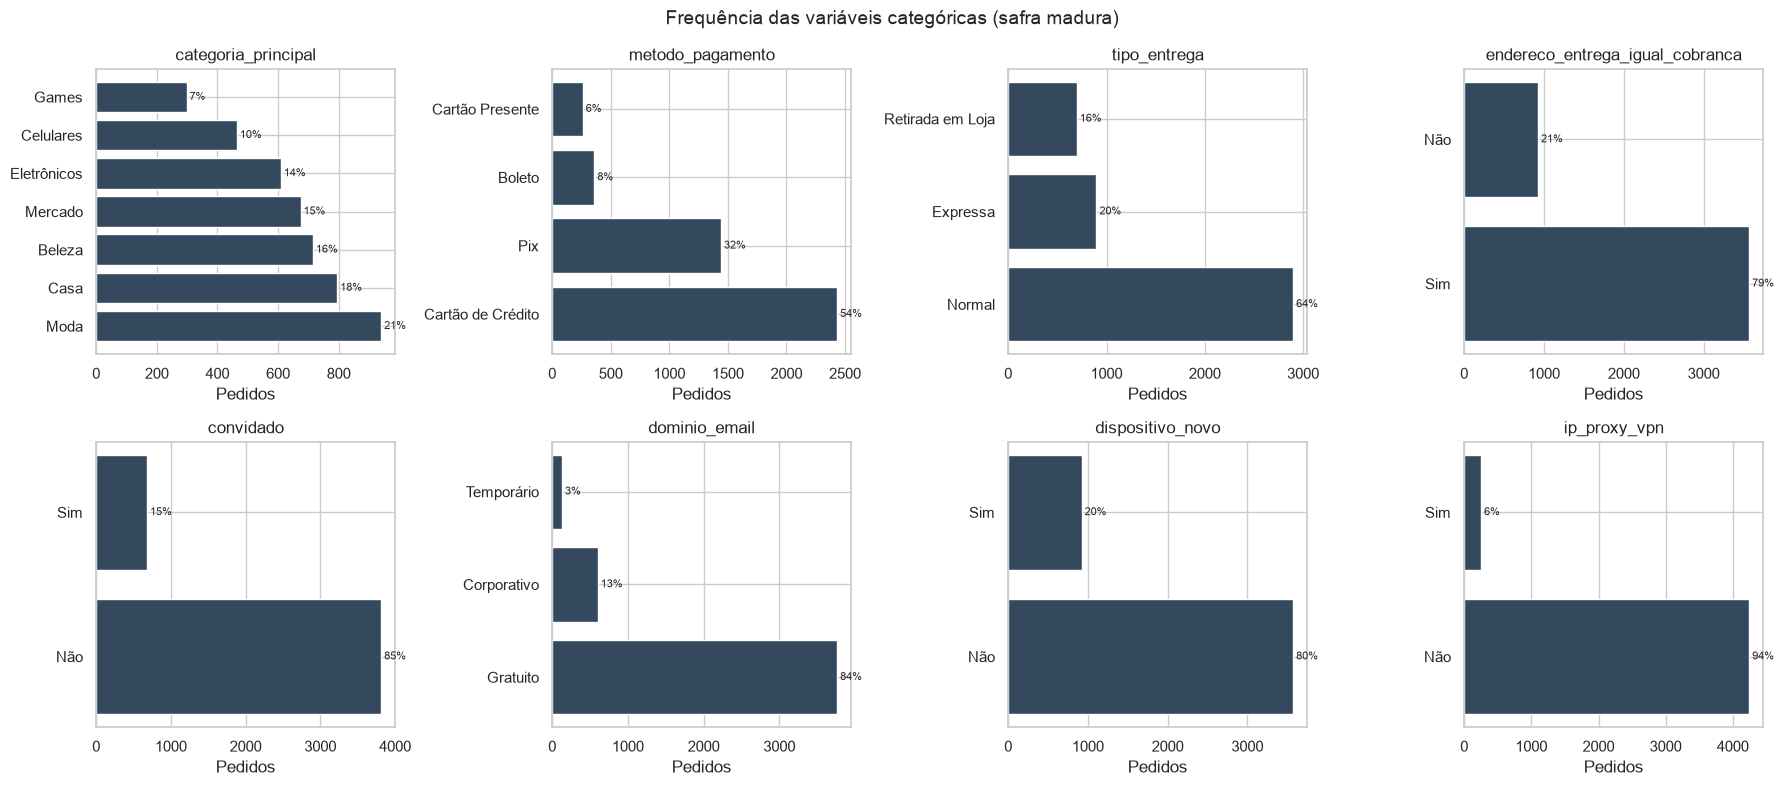

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flat, categoricas):
    vc = base[c].value_counts()
    ax.barh(vc.index.astype(str), vc.values, color='#34495e')
    ax.set_title(c)
    ax.set_xlabel('Pedidos')
    for i, v in enumerate(vc.values):
        ax.text(v, i, f' {100*v/len(base):.0f}%', va='center', fontsize=8)
fig.suptitle('Frequência das variáveis categóricas (safra madura)', fontsize=14)
plt.tight_layout(); plt.show()

In [19]:
for c in categoricas:
    t = pd.DataFrame({'pedidos': base[c].value_counts(), '%': 100 * base[c].value_counts(normalize=True)})
    print(f'\n{c}'); print(t.round(1).to_string())


categoria_principal
                     pedidos     %
categoria_principal               
Moda                     940 20.90
Casa                     795 17.70
Beleza                   715 15.90
Mercado                  674 15.00
Eletrônicos              609 13.50
Celulares                464 10.30
Games                    298  6.60

metodo_pagamento
                   pedidos     %
metodo_pagamento                
Cartão de Crédito     2433 54.10
Pix                   1441 32.10
Boleto                 360  8.00
Cartão Presente        261  5.80

tipo_entrega
                  pedidos     %
tipo_entrega                   
Normal               2899 64.50
Expressa              898 20.00
Retirada em Loja      698 15.50

endereco_entrega_igual_cobranca
                                 pedidos     %
endereco_entrega_igual_cobranca               
Sim                                 3570 79.40
Não                                  925 20.60

convidado
           pedidos     %
convidado        

### Variáveis numéricas

In [20]:
base[numericas].describe(percentiles=[.25, .5, .75, .95]).T.assign(
    assimetria=base[numericas].skew())

,count,mean,std,min,25%,50%,75%,95%,max,assimetria
valor_pedido,"4,490.00","1,029.11","1,425.00",36.24,203.19,380.94,"1,236.24","4,053.08","13,425.91",2.58
qtd_itens,"4,495.00",2.29,1.15,1.00,1.00,2.00,3.00,4.00,8.00,0.94
tentativas_pagamento,"4,495.00",1.15,0.39,1.00,1.00,1.00,1.00,2.00,5.00,2.59
cartoes_cadastrados_30d,"4,495.00",0.30,0.55,0.00,0.00,0.00,1.00,1.00,4.00,1.83
tempo_conta_dias,"3,814.00",483.53,493.25,0.00,132.00,339.00,669.75,"1,469.35","5,578.00",2.23
pedidos_anteriores,"4,495.00",3.42,4.43,0.00,0.00,2.00,5.00,12.00,36.00,2.14
contas_mesmo_dispositivo,"4,495.00",1.18,0.71,1.00,1.00,1.00,1.00,2.00,8.00,6.48
tempo_sessao_min,"4,489.00",12.85,8.22,1.10,7.20,10.80,16.20,28.70,90.70,1.92


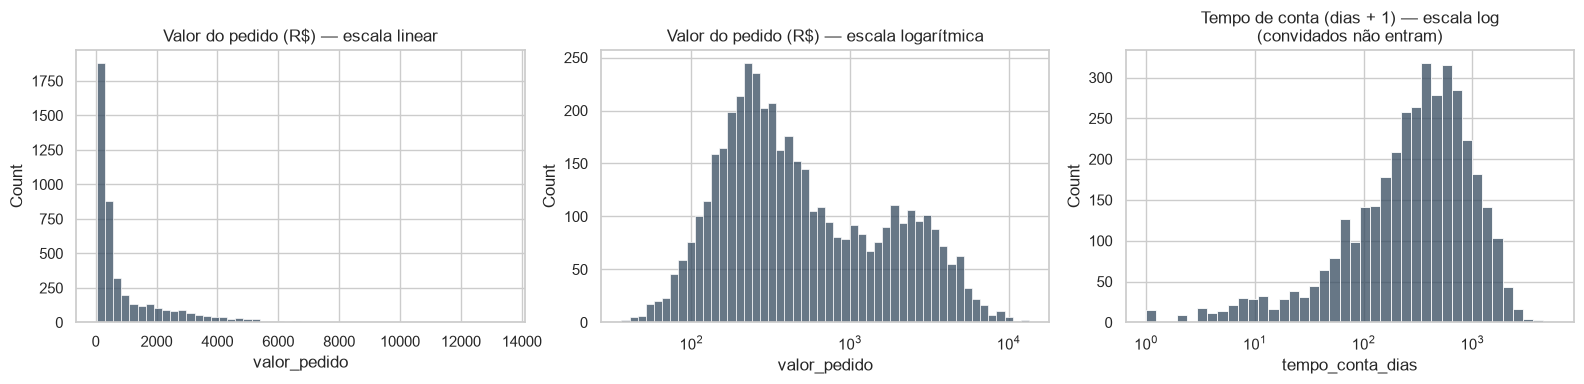

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(base['valor_pedido'], bins=50, ax=axes[0], color='#34495e')
axes[0].set_title('Valor do pedido (R$) — escala linear')
sns.histplot(base['valor_pedido'], bins=50, log_scale=True, ax=axes[1], color='#34495e')
axes[1].set_title('Valor do pedido (R$) — escala logarítmica')
sns.histplot(base['tempo_conta_dias'] + 1, bins=40, log_scale=True, ax=axes[2], color='#34495e')
axes[2].set_title('Tempo de conta (dias + 1) — escala log\n(convidados não entram)')
plt.tight_layout(); plt.show()

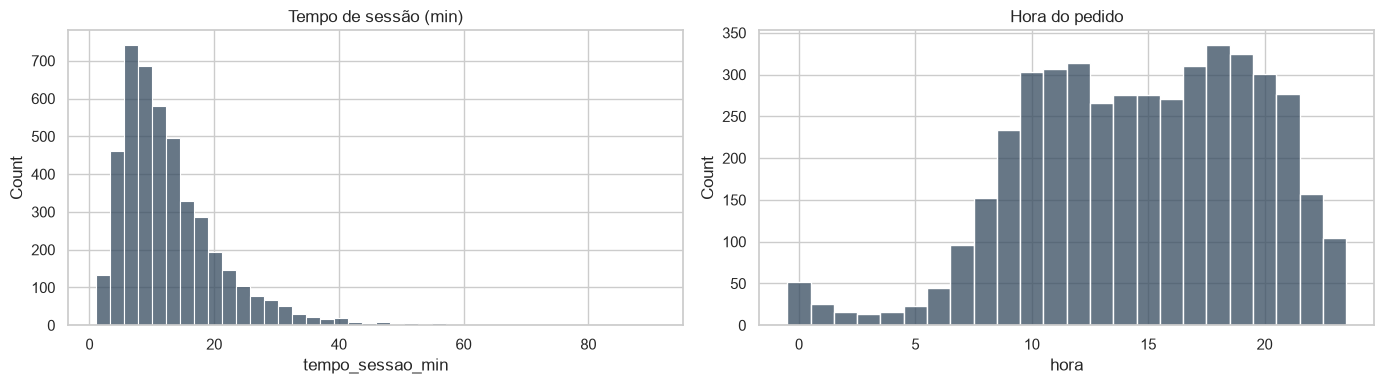

qtd_itens: {1: 1256, 2: 1588, 3: 1034, 4: 414, 5: 140, 6: 52, 7: 10, 8: 1}
tentativas_pagamento: {1: 3855, 2: 590, 3: 49, 5: 1}
cartoes_cadastrados_30d: {0: 3331, 1: 1000, 2: 152, 3: 9, 4: 3}
pedidos_anteriores: {0: 1441, 1: 582, 2: 561, 3: 370, 4: 315, 5: 211, 6: 208, 7: 147, 8: 111, 9: 97, 10: 98, 11: 74, 12: 56, 13: 56, 14: 42, 15: 23, 16: 20, 17: 18, 18: 13, 19: 11, 20: 5, 21: 3, 22: 3, 23: 7, 24: 4, 25: 5, 27: 2, 28: 5, 29: 2, 30: 1, 33: 2, 35: 1, 36: 1}
contas_mesmo_dispositivo: {1: 4011, 2: 386, 3: 30, 4: 11, 5: 13, 6: 18, 7: 10, 8: 16}


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(base['tempo_sessao_min'], bins=40, ax=axes[0], color='#34495e')
axes[0].set_title('Tempo de sessão (min)')
sns.histplot(base['hora'], bins=24, discrete=True, ax=axes[1], color='#34495e')
axes[1].set_title('Hora do pedido')
plt.tight_layout(); plt.show()

discretas = ['qtd_itens', 'tentativas_pagamento', 'cartoes_cadastrados_30d', 'pedidos_anteriores', 'contas_mesmo_dispositivo']
for c in discretas:
    print(f'{c}: {base[c].value_counts().sort_index().to_dict()}')

> ✍️ **O que as distribuições revelam** — *texto do Leandro*
>
> - Média × mediana: quais variáveis têm cauda longa? A escala log ajudou a ler `valor_pedido`?
> - Quais grupos são pequenos (ex.: domínio temporário, 3+ contas no mesmo aparelho) e exigirão cautela na Etapa 6?
>
> _[escrever aqui]_

## Etapa 6 — Análise bivariada (uma variável explicativa × `fraude`)

Para cada hipótese: **taxa de fraude por grupo com o n de cada grupo** (barras cinzas = n < 30) e,
para numéricas, comparação das distribuições (boxplot e medianas) e taxa por faixa.
A linha tracejada é a taxa geral.

> *Diferenças entre grupos não demonstram, por si só, relações causais.*

In [23]:
# faixas para as numéricas (usadas nas tabelas de taxa)
base['faixa_valor'] = pd.qcut(base['valor_pedido'], 5,
                              labels=['Q1 (menor)', 'Q2', 'Q3', 'Q4', 'Q5 (maior)'])
base['faixa_conta'] = pd.cut(base['tempo_conta_dias'], [-1, 7, 30, 180, 365, np.inf],
                             labels=['0–7 d', '8–30 d', '31–180 d', '181–365 d', '> 1 ano'])
base['faixa_conta'] = base['faixa_conta'].cat.add_categories('convidado').fillna('convidado')
base['faixa_pedidos_ant'] = pd.cut(base['pedidos_anteriores'], [-1, 0, 1, 4, np.inf],
                                   labels=['0', '1', '2–4', '5+'])
base['faixa_disp'] = pd.cut(base['contas_mesmo_dispositivo'], [0, 1, 2, np.inf], labels=['1', '2', '3+'])
base['faixa_cartoes'] = pd.cut(base['cartoes_cadastrados_30d'], [-1, 0, 1, np.inf], labels=['0', '1', '2+'])
base['faixa_tentativas'] = pd.cut(base['tentativas_pagamento'], [0, 1, 2, np.inf], labels=['1', '2', '3+'])
base['faixa_sessao'] = pd.qcut(base['tempo_sessao_min'], 5,
                               labels=['Q1 (mais curta)', 'Q2', 'Q3', 'Q4', 'Q5 (mais longa)'])
base['periodo'] = pd.cut(base['hora'], [-1, 5, 11, 17, 23], labels=['madrugada (0–5h)', 'manhã', 'tarde', 'noite'])

def comparar_numerica(var, titulo, log=False):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    sns.boxplot(data=base, x=var, y='fraude', order=['Não', 'Sim'], ax=ax, color='#bbbbbb',
                log_scale=log, showfliers=True, flierprops={'markersize': 2})
    ax.set_title(titulo); ax.set_ylabel('Fraude')
    plt.show()
    return base.groupby('fraude')[var].describe()[['count', '25%', '50%', '75%', 'mean']]

### H1 — Alto valor e produtos de fácil revenda

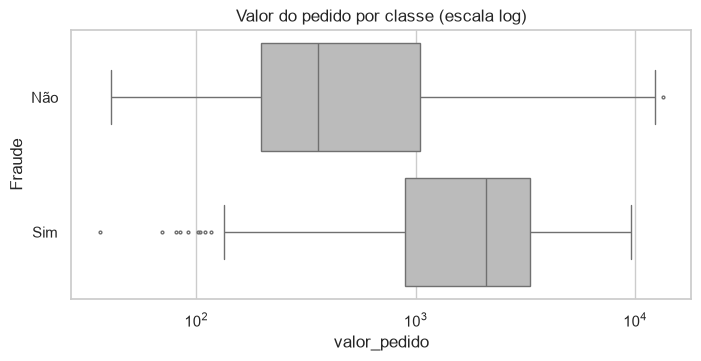

,count,25%,50%,75%,mean
fraude,,,,,
Não,"4,207.00",197.25,358.19,"1,047.10",938.63
Sim,283.00,893.52,"2,085.54","3,312.74","2,374.13"


In [24]:
comparar_numerica('valor_pedido', 'Valor do pedido por classe (escala log)', log=True)

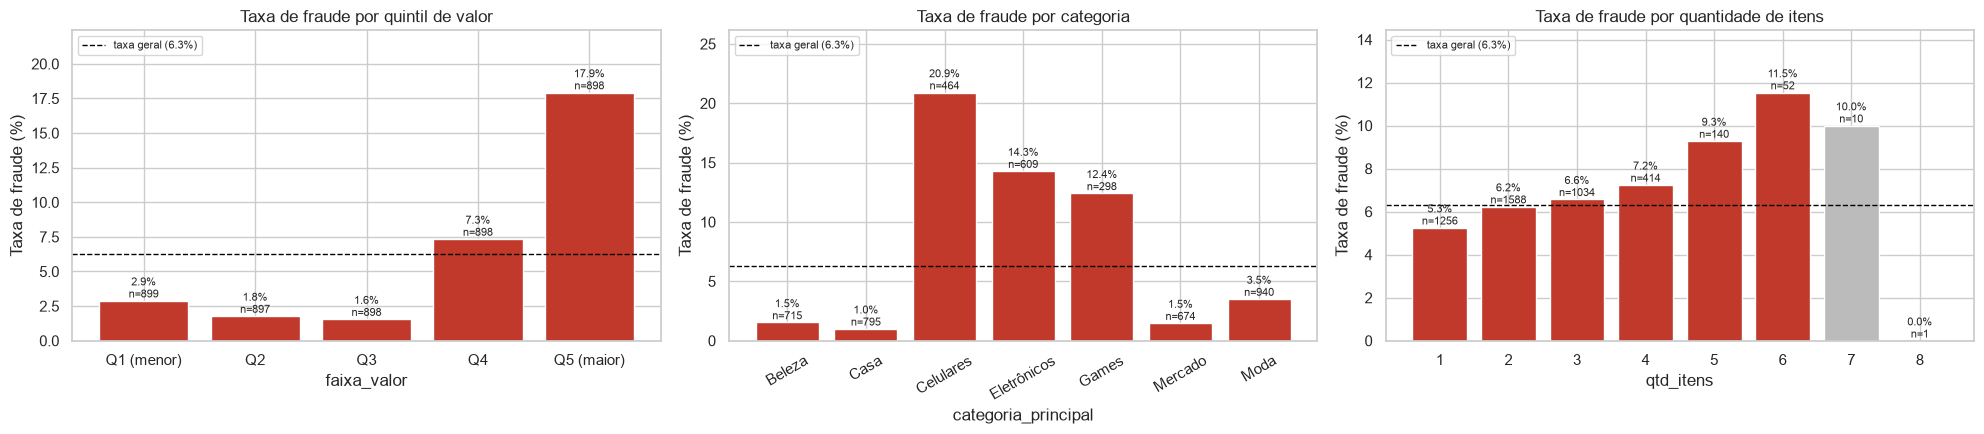

,pedidos,fraudes,taxa_fraude_%,part_pedidos_%,part_fraudes_%,razao_vs_geral,n_pequeno
categoria_principal,,,,,,,
Celulares,464,97,20.91,10.32,34.28,3.32,
Eletrônicos,609,87,14.29,13.55,30.74,2.27,
Games,298,37,12.42,6.63,13.07,1.97,
Moda,940,33,3.51,20.91,11.66,0.56,
Beleza,715,11,1.54,15.91,3.89,0.24,
Mercado,674,10,1.48,14.99,3.53,0.24,
Casa,795,8,1.01,17.69,2.83,0.16,


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
t_valor = grafico_taxa(base, 'faixa_valor', 'Taxa de fraude por quintil de valor', ax=axes[0])
t_cat = grafico_taxa(base, 'categoria_principal', 'Taxa de fraude por categoria', ax=axes[1], rot=30)
t_itens = grafico_taxa(base, 'qtd_itens', 'Taxa de fraude por quantidade de itens', ax=axes[2])
plt.tight_layout(); plt.show()
display(t_cat.sort_values('taxa_fraude_%', ascending=False))

### H2 — Meio de pagamento e teste de cartão

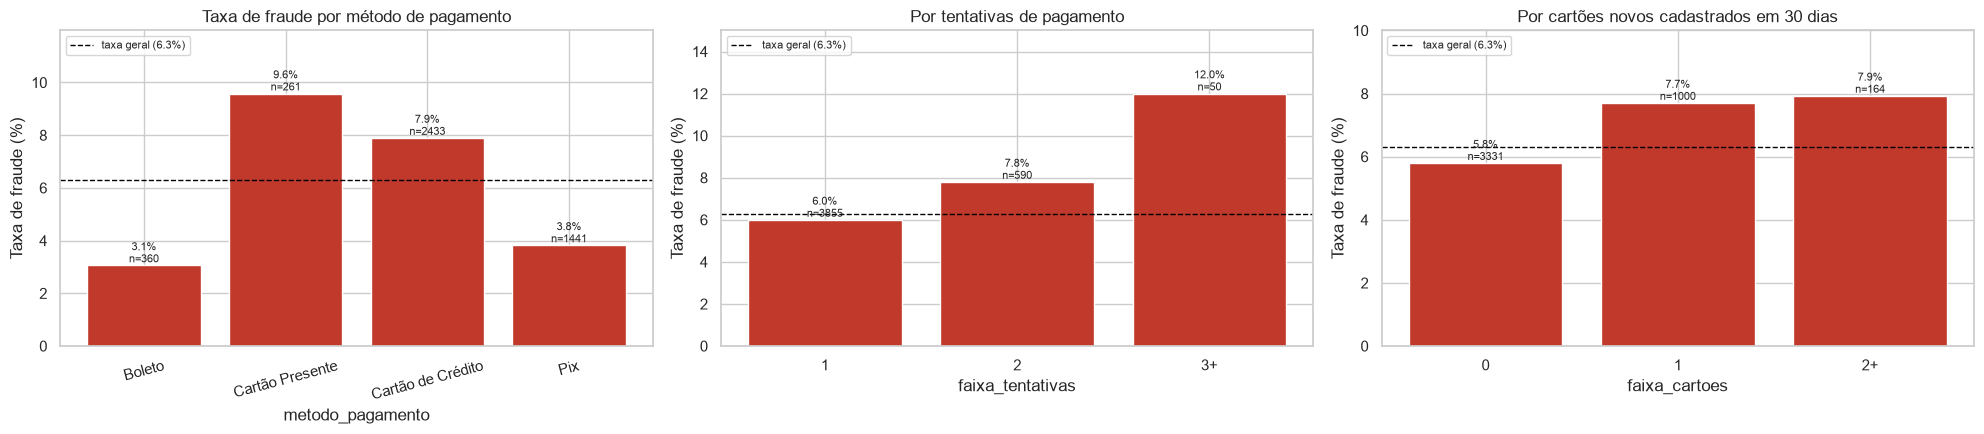

,pedidos,fraudes,taxa_fraude_%,part_pedidos_%,part_fraudes_%,razao_vs_geral,n_pequeno
metodo_pagamento,,,,,,,
Boleto,360,11,3.06,8.01,3.89,0.49,
Cartão Presente,261,25,9.58,5.81,8.83,1.52,
Cartão de Crédito,2433,192,7.89,54.13,67.84,1.25,
Pix,1441,55,3.82,32.06,19.43,0.61,


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
t_pag = grafico_taxa(base, 'metodo_pagamento', 'Taxa de fraude por método de pagamento', ax=axes[0], rot=15)
t_tent = grafico_taxa(base, 'faixa_tentativas', 'Por tentativas de pagamento', ax=axes[1])
t_cart = grafico_taxa(base, 'faixa_cartoes', 'Por cartões novos cadastrados em 30 dias', ax=axes[2])
plt.tight_layout(); plt.show()
display(t_pag)

### H3 — Logística e entrega

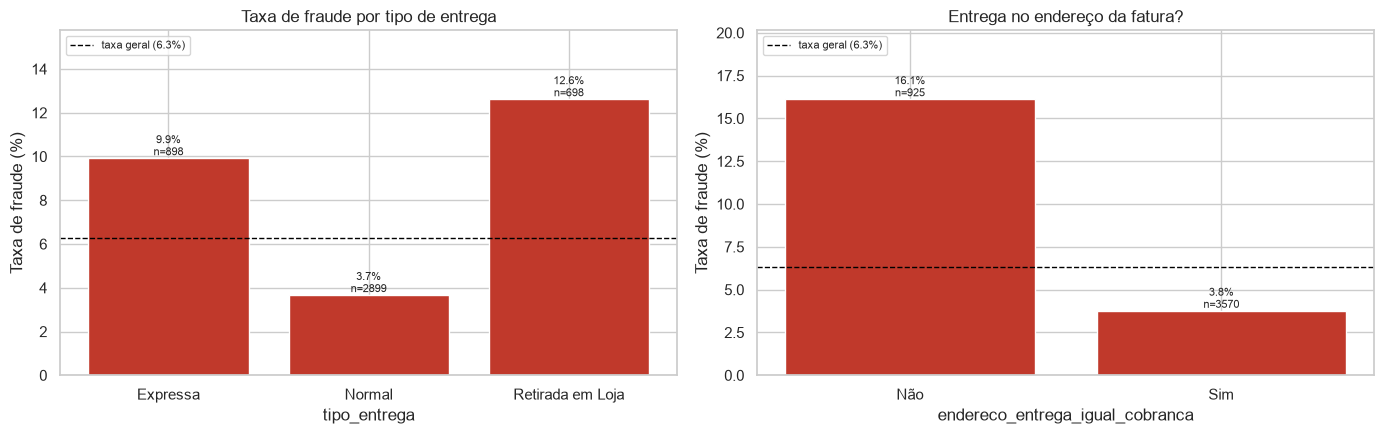

,pedidos,fraudes,taxa_fraude_%,part_pedidos_%,part_fraudes_%,razao_vs_geral,n_pequeno
tipo_entrega,,,,,,,
Expressa,898,89,9.91,19.98,31.45,1.57,
Normal,2899,106,3.66,64.49,37.46,0.58,
Retirada em Loja,698,88,12.61,15.53,31.10,2.00,


,pedidos,fraudes,taxa_fraude_%,part_pedidos_%,part_fraudes_%,razao_vs_geral,n_pequeno
endereco_entrega_igual_cobranca,,,,,,,
Não,925,149,16.11,20.58,52.65,2.56,
Sim,3570,134,3.75,79.42,47.35,0.60,


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
t_ent = grafico_taxa(base, 'tipo_entrega', 'Taxa de fraude por tipo de entrega', ax=axes[0])
t_end = grafico_taxa(base, 'endereco_entrega_igual_cobranca', 'Entrega no endereço da fatura?', ax=axes[1])
plt.tight_layout(); plt.show()
display(t_ent); display(t_end)

### H4 — Identidade e histórico da conta

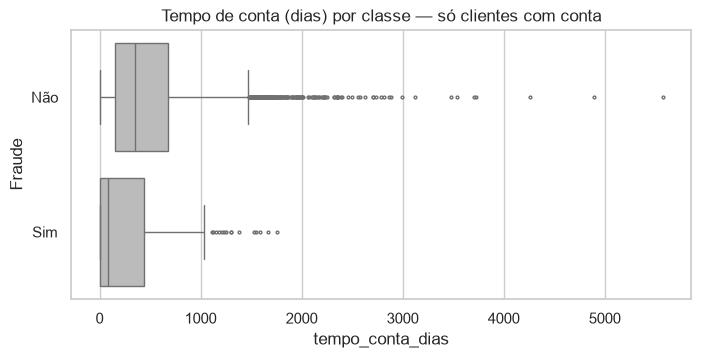

,count,25%,50%,75%,mean
fraude,,,,,
Não,"3,586.00",148.00,350.00,679.00,496.28
Sim,228.00,7.00,87.00,437.75,283.05


In [28]:
comparar_numerica('tempo_conta_dias', 'Tempo de conta (dias) por classe — só clientes com conta')

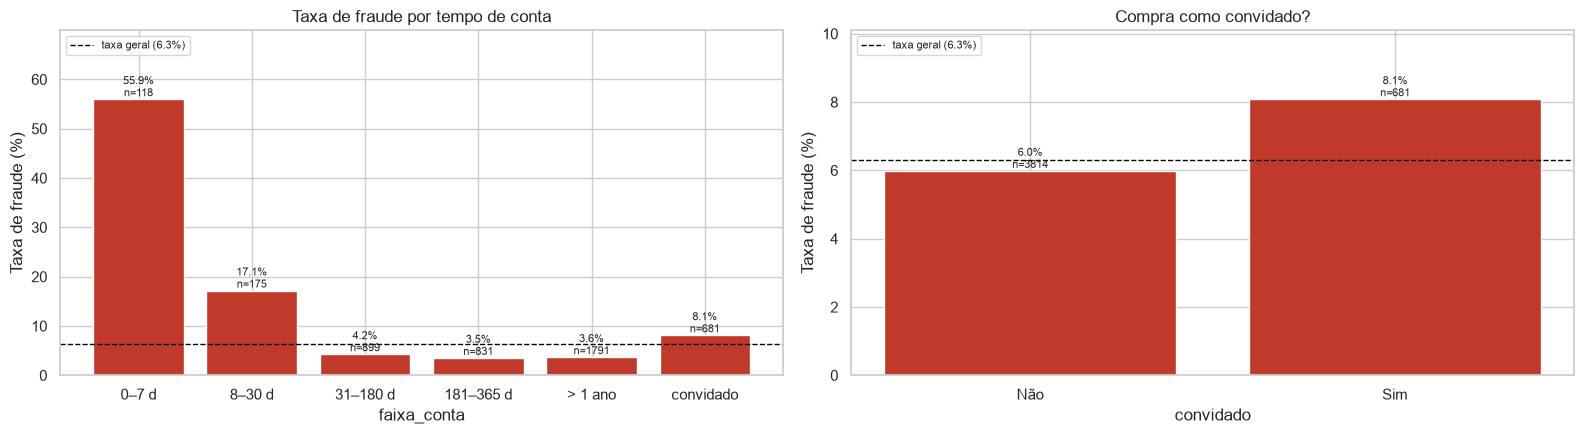

,pedidos,fraudes,taxa_fraude_%,part_pedidos_%,part_fraudes_%,razao_vs_geral,n_pequeno
faixa_conta,,,,,,,
0–7 d,118,66,55.93,2.63,23.32,8.88,
8–30 d,175,30,17.14,3.89,10.60,2.72,
31–180 d,899,38,4.23,20.00,13.43,0.67,
181–365 d,831,29,3.49,18.49,10.25,0.55,
> 1 ano,1791,65,3.63,39.84,22.97,0.58,
convidado,681,55,8.08,15.15,19.43,1.28,


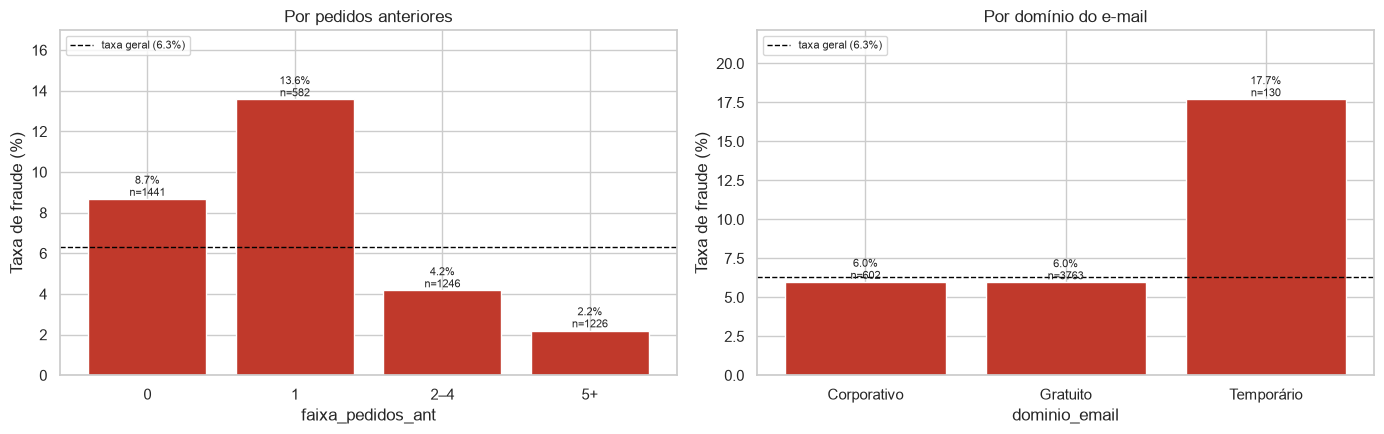

,pedidos,fraudes,taxa_fraude_%,part_pedidos_%,part_fraudes_%,razao_vs_geral,n_pequeno
dominio_email,,,,,,,
Corporativo,602,36,5.98,13.39,12.72,0.95,
Gratuito,3763,224,5.95,83.72,79.15,0.95,
Temporário,130,23,17.69,2.89,8.13,2.81,


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
t_conta = grafico_taxa(base, 'faixa_conta', 'Taxa de fraude por tempo de conta', ax=axes[0])
t_conv = grafico_taxa(base, 'convidado', 'Compra como convidado?', ax=axes[1])
plt.tight_layout(); plt.show()
display(t_conta)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
t_ped = grafico_taxa(base, 'faixa_pedidos_ant', 'Por pedidos anteriores', ax=axes[0])
t_email = grafico_taxa(base, 'dominio_email', 'Por domínio do e-mail', ax=axes[1])
plt.tight_layout(); plt.show()
display(t_email)

### H5 — Ação organizada (dispositivo e rede)

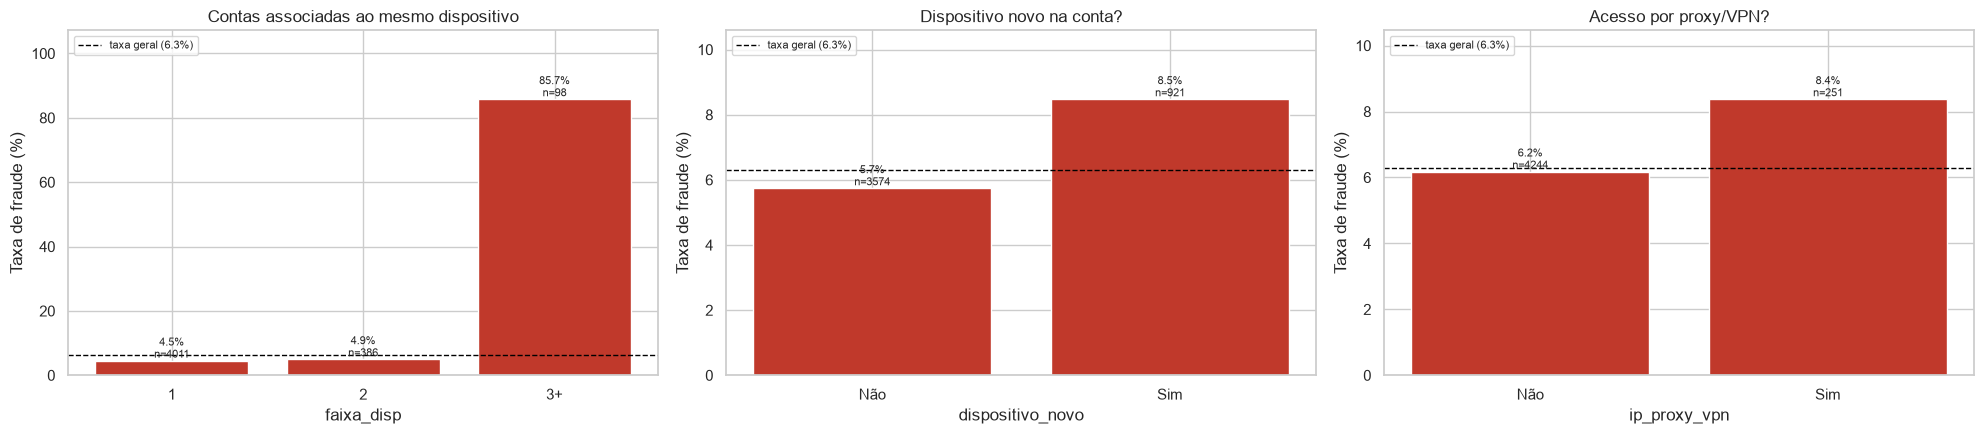

,pedidos,fraudes,taxa_fraude_%,part_pedidos_%,part_fraudes_%,razao_vs_geral,n_pequeno
contas_mesmo_dispositivo,,,,,,,
1,4011,180,4.49,89.23,63.60,0.71,
2,386,19,4.92,8.59,6.71,0.78,
3,30,16,53.33,0.67,5.65,8.47,
4,11,11,100.00,0.24,3.89,15.88,⚠️
5,13,13,100.00,0.29,4.59,15.88,⚠️
6,18,18,100.00,0.40,6.36,15.88,⚠️
7,10,10,100.00,0.22,3.53,15.88,⚠️
8,16,16,100.00,0.36,5.65,15.88,⚠️


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
t_disp = grafico_taxa(base, 'faixa_disp', 'Contas associadas ao mesmo dispositivo', ax=axes[0])
t_dnovo = grafico_taxa(base, 'dispositivo_novo', 'Dispositivo novo na conta?', ax=axes[1])
t_vpn = grafico_taxa(base, 'ip_proxy_vpn', 'Acesso por proxy/VPN?', ax=axes[2])
plt.tight_layout(); plt.show()

# detalhe: a taxa cresce com o número de contas no aparelho?
display(tabela_taxa(base, 'contas_mesmo_dispositivo'))

### H6 — Comportamento na sessão e momento da compra

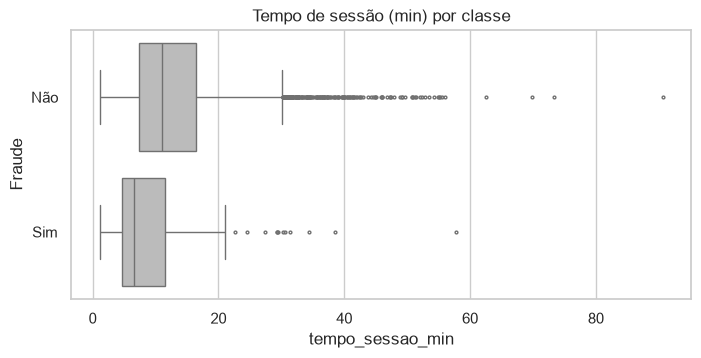

,count,25%,50%,75%,mean
fraude,,,,,
Não,"4,206.00",7.40,11.10,16.50,13.11
Sim,283.00,4.70,6.60,11.55,9.02


In [31]:
comparar_numerica('tempo_sessao_min', 'Tempo de sessão (min) por classe')

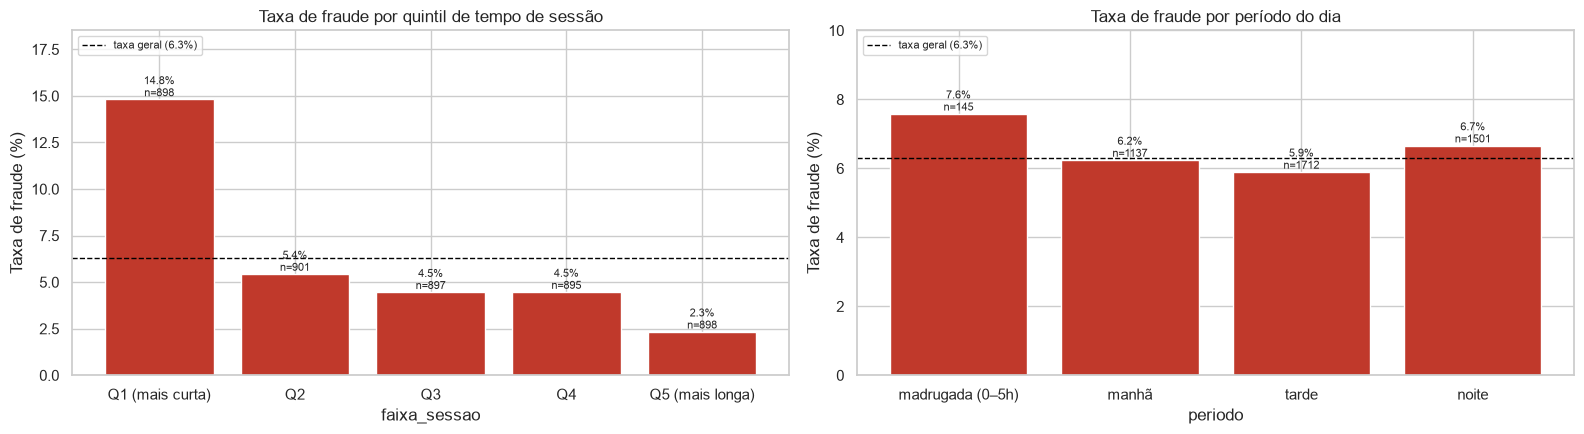

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
t_sessao = grafico_taxa(base, 'faixa_sessao', 'Taxa de fraude por quintil de tempo de sessão', ax=axes[0])
t_periodo = grafico_taxa(base, 'periodo', 'Taxa de fraude por período do dia', ax=axes[1])
plt.tight_layout(); plt.show()

### Quadro de controle: variáveis sem hipótese

Verificação rápida das variáveis deixadas fora, para registrar que a exclusão não escondeu um padrão forte.

In [33]:
for c in ['canal_venda', 'cupom_utilizado', 'uf_entrega']:
    t = tabela_taxa(base, c)[['pedidos', 'taxa_fraude_%']]
    print(f'\n{c}'); print(t.round(1).to_string())


canal_venda
             pedidos  taxa_fraude_%
canal_venda                        
App             1811           5.80
Marketplace      897           5.60
Site            1787           7.20

cupom_utilizado
                 pedidos  taxa_fraude_%
cupom_utilizado                        
Não                 3105           6.10
Sim                 1390           6.70

uf_entrega
            pedidos  taxa_fraude_%
uf_entrega                        
BA              269           5.90
CE              191           4.20
DF              176           6.20
GO              163           8.60
MG              506           7.10
PE              235           7.70
PR              326           7.70
RJ              590           6.40
RS              288           5.60
SC              250           7.60
SP             1501           5.50


### Comparação da força das associações

Para cada variável, o grupo de **maior taxa** com pelo menos 30 pedidos, comparado à taxa geral
(`razao_vs_geral` = quantas vezes a taxa do grupo supera a taxa geral).

In [34]:
analisadas = {
    'H1': ['faixa_valor', 'categoria_principal', 'qtd_itens'],
    'H2': ['metodo_pagamento', 'faixa_tentativas', 'faixa_cartoes'],
    'H3': ['tipo_entrega', 'endereco_entrega_igual_cobranca'],
    'H4': ['faixa_conta', 'convidado', 'faixa_pedidos_ant', 'dominio_email'],
    'H5': ['faixa_disp', 'dispositivo_novo', 'ip_proxy_vpn'],
    'H6': ['faixa_sessao', 'periodo'],
}
linhas = []
for h, variaveis in analisadas.items():
    for v in variaveis:
        t = tabela_taxa(base, v)
        t = t[t['pedidos'] >= MIN_N]
        g = t['taxa_fraude_%'].idxmax()
        linhas.append({'hipótese': h, 'variável': v, 'grupo de maior taxa': str(g),
                       'pedidos': t.loc[g, 'pedidos'], 'taxa_%': t.loc[g, 'taxa_fraude_%'],
                       'menor taxa entre grupos_%': t['taxa_fraude_%'].min(),
                       'razao_vs_geral': t.loc[g, 'razao_vs_geral'],
                       'part_pedidos_%': t.loc[g, 'part_pedidos_%'], 'part_fraudes_%': t.loc[g, 'part_fraudes_%']})
forca = pd.DataFrame(linhas).sort_values('razao_vs_geral', ascending=False).reset_index(drop=True)
forca

,hipótese,variável,grupo de maior taxa,pedidos,taxa_%,menor taxa entre grupos_%,razao_vs_geral,part_pedidos_%,part_fraudes_%
0,H5,faixa_disp,3+,98,85.71,4.49,13.61,2.18,29.68
1,H4,faixa_conta,0–7 d,118,55.93,3.49,8.88,2.63,23.32
2,H1,categoria_principal,Celulares,464,20.91,1.01,3.32,10.32,34.28
3,H1,faixa_valor,Q5 (maior),898,17.93,1.56,2.85,20.00,56.89
4,H4,dominio_email,Temporário,130,17.69,5.95,2.81,2.89,8.13
5,H3,endereco_entrega_igual_cobranca,Não,925,16.11,3.75,2.56,20.58,52.65
6,H6,faixa_sessao,Q1 (mais curta),898,14.81,2.34,2.35,20.00,47.00
7,H4,faixa_pedidos_ant,1,582,13.57,2.20,2.16,12.95,27.92
8,H3,tipo_entrega,Retirada em Loja,698,12.61,3.66,2.00,15.53,31.10
9,H2,faixa_tentativas,3+,50,12.00,5.99,1.91,1.11,2.12


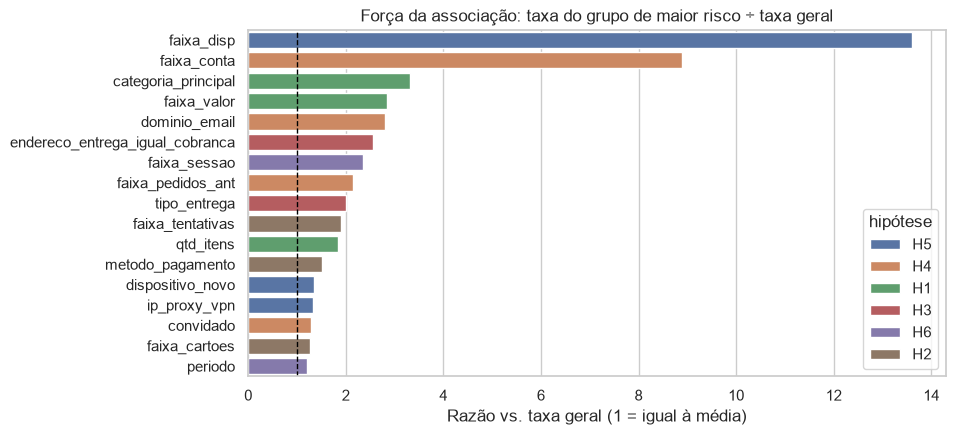

In [35]:
ax = sns.barplot(data=forca, y='variável', x='razao_vs_geral', hue='hipótese', dodge=False)
ax.axvline(1, color='black', ls='--', lw=1)
ax.set_title('Força da associação: taxa do grupo de maior risco ÷ taxa geral')
ax.set_xlabel('Razão vs. taxa geral (1 = igual à média)'); ax.set_ylabel('')
plt.show()

### Participação dos grupos de maior risco: pedidos × fraudes

Um grupo de risco é relevante para o negócio quando **concentra fraudes muito acima do seu peso em pedidos**.
Um grupo com taxa alta, mas que responde por pouquíssimas fraudes, tem impacto limitado.

In [36]:
grupos_risco = {
    'Conta com até 7 dias':            base['faixa_conta'] == '0–7 d',
    '3+ contas no mesmo dispositivo':  base['faixa_disp'] == '3+',
    'Entrega fora do end. da fatura':  base['endereco_entrega_igual_cobranca'] == 'Não',
    'Celulares/Eletrônicos/Games':     base['categoria_principal'].isin(['Celulares', 'Eletrônicos', 'Games']),
    'Quintil de maior valor':          base['faixa_valor'] == 'Q5 (maior)',
    'Retirada em loja ou expressa':    base['tipo_entrega'].isin(['Retirada em Loja', 'Expressa']),
    'E-mail temporário':               base['dominio_email'] == 'Temporário',
    'Cartão de crédito':               base['metodo_pagamento'] == 'Cartão de Crédito',
    'Compra como convidado':           base['convidado'] == 'Sim',
}
total_fraudes = base['fraude_bin'].sum()
part = pd.DataFrame({
    'pedidos': {k: m.sum() for k, m in grupos_risco.items()},
    'part_pedidos_%': {k: 100 * m.mean() for k, m in grupos_risco.items()},
    'part_fraudes_%': {k: 100 * base.loc[m, 'fraude_bin'].sum() / total_fraudes for k, m in grupos_risco.items()},
    'taxa_fraude_%': {k: 100 * base.loc[m, 'fraude_bin'].mean() for k, m in grupos_risco.items()},
})
part['concentração (fraudes ÷ pedidos)'] = part['part_fraudes_%'] / part['part_pedidos_%']
part = part.sort_values('concentração (fraudes ÷ pedidos)', ascending=False)
part

,pedidos,part_pedidos_%,part_fraudes_%,taxa_fraude_%,concentração (fraudes ÷ pedidos)
3+ contas no mesmo dispositivo,98,2.18,29.68,85.71,13.61
Conta com até 7 dias,118,2.63,23.32,55.93,8.88
Quintil de maior valor,898,19.98,56.89,17.93,2.85
E-mail temporário,130,2.89,8.13,17.69,2.81
Celulares/Eletrônicos/Games,1371,30.50,78.09,16.12,2.56
Entrega fora do end. da fatura,925,20.58,52.65,16.11,2.56
Retirada em loja ou expressa,1596,35.51,62.54,11.09,1.76
Compra como convidado,681,15.15,19.43,8.08,1.28
Cartão de crédito,2433,54.13,67.84,7.89,1.25


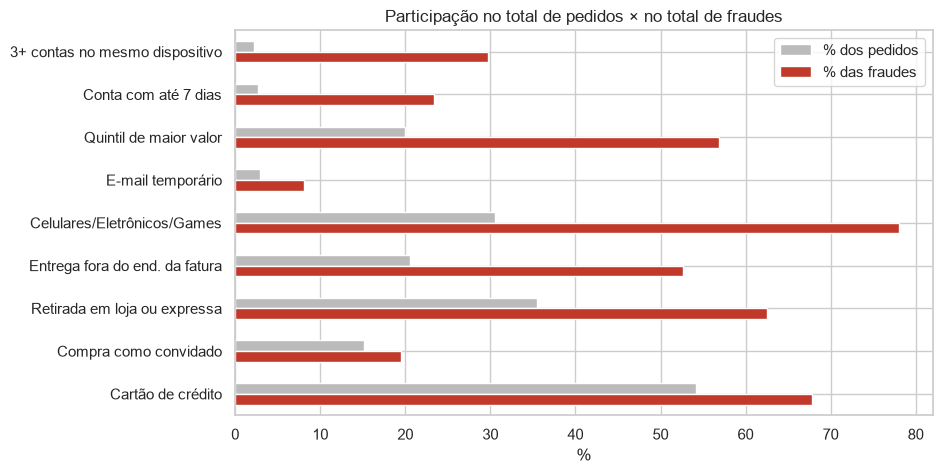

In [37]:
ax = part[['part_pedidos_%', 'part_fraudes_%']].plot.barh(color=['#bbbbbb', '#c0392b'], figsize=(9, 5))
ax.invert_yaxis()
ax.set_title('Participação no total de pedidos × no total de fraudes')
ax.set_xlabel('%'); ax.legend(['% dos pedidos', '% das fraudes'])
plt.show()

### Variáveis que podem medir a mesma coisa: a associação se mantém dentro dos grupos da outra?

Quando duas explicativas andam juntas, a associação de uma com a fraude pode ser **reflexo da outra**.
Teste: comparar a taxa de fraude de uma variável **dentro de cada grupo** da outra.

**(a) Valor do pedido × categoria** — o alto valor é risco em si, ou só reflete celulares e eletrônicos (que são caros)?

In [38]:
base['grupo_categoria'] = np.where(base['categoria_principal'].isin(['Celulares', 'Eletrônicos', 'Games']),
                                   'Celulares/Eletrônicos/Games', 'Demais categorias')

print('Valor mediano por categoria:')
print(base.groupby('categoria_principal')['valor_pedido'].median().sort_values().round(0).to_string())

# Celular é caro por natureza: comparar "valor alto" com a mediana geral misturaria valor e categoria.
# Por isso, o valor é classificado como alto ou baixo em relação à mediana DA PRÓPRIA categoria.
mediana_cat = base.groupby('categoria_principal')['valor_pedido'].transform('median')
base['valor_na_categoria'] = np.where(base['valor_pedido'] >= mediana_cat,
                                      'acima da mediana da categoria', 'abaixo da mediana da categoria')
base.loc[base['valor_pedido'].isna(), 'valor_na_categoria'] = np.nan

estrat = base.pivot_table(index='categoria_principal', columns='valor_na_categoria', values='fraude_bin',
                          aggfunc=['mean', 'size'])
estrat

Valor mediano por categoria:
categoria_principal
Beleza          156.00
Moda            228.00
Mercado         280.00
Casa            450.00
Games         1,137.00
Eletrônicos   2,484.00
Celulares     2,793.00


mean  \
valor_na_categoria  abaixo da mediana da categoria   
categoria_principal                                  
Beleza                                        0.01   
Casa                                          0.01   
Celulares                                     0.19   
Eletrônicos                                   0.12   
Games                                         0.11   
Mercado                                       0.02   
Moda                                          0.04   

                                                   \
valor_na_categoria  acima da mediana da categoria   
categoria_principal                                 
Beleza                                       0.02   
Casa                                         0.01   
Celulares                                    0.23   
Eletrônicos                                  0.16   
Games                                        0.14   
Mercado                                      0.01   
Moda                                         0.03   

                                              size  \
valor_na_categoria  abaixo da mediana da categoria   
categoria_principal                                  
Beleza                                         357   
Casa                                           396   
Celulares                                      231   
Eletrônicos                                    304   
Games                                          149   
Mercado                                        337   
Moda                                           469   

                                                   
valor_na_categoria  acima da mediana da categoria  
categoria_principal                                
Beleza                                        357  
Casa                                          397  
Celulares                                     232  
Eletrônicos                                   305  
Games                                         149  
Mercado                                       337  
Moda                                          470

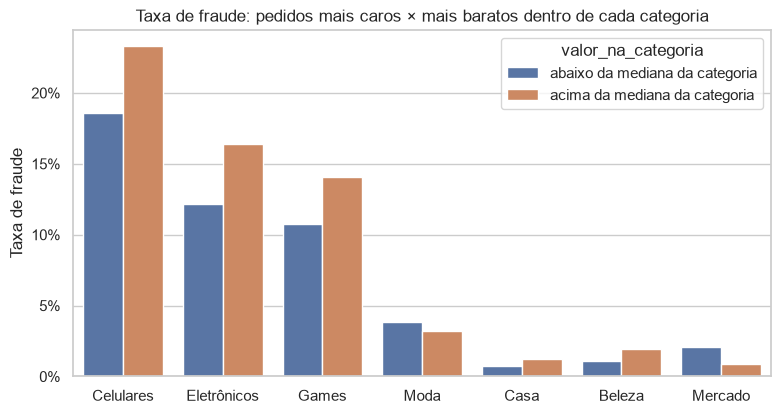

In [39]:
ax = sns.barplot(data=base, x='categoria_principal', y='fraude_bin', hue='valor_na_categoria', errorbar=None,
                 order=['Celulares', 'Eletrônicos', 'Games', 'Moda', 'Casa', 'Beleza', 'Mercado'])
ax.set_title('Taxa de fraude: pedidos mais caros × mais baratos dentro de cada categoria')
ax.set_ylabel('Taxa de fraude'); ax.set_xlabel('')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{100*y:.0f}%'))
plt.show()

**(b) Convidado × conta nova** — ambos medem ausência de histórico. A conta nova segue arriscada quando comparada só entre quem tem conta?

In [40]:
tabela_taxa(base, 'faixa_conta')[['pedidos', 'fraudes', 'taxa_fraude_%']]

,pedidos,fraudes,taxa_fraude_%
faixa_conta,,,
0–7 d,118,66,55.93
8–30 d,175,30,17.14
31–180 d,899,38,4.23
181–365 d,831,29,3.49
> 1 ano,1791,65,3.63
convidado,681,55,8.08


**(c) Dispositivo novo × contas no mesmo dispositivo** — o "dispositivo novo" é risco em si, ou só porque aparelhos compartilhados por muitas contas são novos para cada uma delas?

In [41]:
base.pivot_table(index='dispositivo_novo', columns='faixa_disp', values='fraude_bin',
                 aggfunc=['mean', 'size'], observed=True)

mean            size         
faixa_disp          1    2   3+     1    2  3+
dispositivo_novo                              
Não              0.03 0.04 0.89  3175  306  93
Sim              0.08 0.10 0.20   836   80   5

**(d) Tipo de entrega × endereço diferente da fatura** — retirada em loja e entrega expressa seguem arriscadas quando o endereço é o mesmo da fatura?

In [42]:
base.pivot_table(index='tipo_entrega', columns='endereco_entrega_igual_cobranca', values='fraude_bin',
                 aggfunc=['mean', 'size'])

mean      size      
endereco_entrega_igual_cobranca  Não  Sim  Não   Sim
tipo_entrega                                        
Expressa                        0.25 0.06  193   705
Normal                          0.08 0.03  548  2351
Retirada em Loja                0.30 0.06  184   514

**(e) Cartão de crédito × categoria** — o risco do cartão permanece dentro do mesmo grupo de categoria?

In [43]:
base.pivot_table(index='metodo_pagamento', columns='grupo_categoria', values='fraude_bin',
                 aggfunc=['mean', 'size'])

mean                    \
grupo_categoria   Celulares/Eletrônicos/Games Demais categorias   
metodo_pagamento                                                  
Boleto                                   0.08              0.01   
Cartão Presente                          0.28              0.02   
Cartão de Crédito                        0.20              0.03   
Pix                                      0.10              0.01   

                                         size                    
grupo_categoria   Celulares/Eletrônicos/Games Demais categorias  
metodo_pagamento                                                 
Boleto                                    112               248  
Cartão Presente                            75               186  
Cartão de Crédito                         735              1698  
Pix                                       449               992

### Retrato do pedido fraudulento

Quantos dos **sinais de risco mais fortes** cada pedido apresenta — e como isso se distribui entre fraudes
e pedidos legítimos. Ainda é descritivo: contar sinais não é um modelo, e a lista de sinais vem da própria
análise acima.

In [44]:
sinais = {
    'conta_ate_30d':     base['faixa_conta'].isin(['0–7 d', '8–30 d']),
    'disp_3mais_contas': base['faixa_disp'] == '3+',
    'end_diferente':     base['endereco_entrega_igual_cobranca'] == 'Não',
    'cat_revendavel':    base['grupo_categoria'] == 'Celulares/Eletrônicos/Games',
}
S = pd.DataFrame(sinais)
base['n_sinais'] = S.sum(axis=1)

print('Frequência de cada sinal entre fraudes e legítimos (%):')
print((100 * S.groupby(base['fraude']).mean()).T.round(1).to_string())

retrato = pd.crosstab(base['n_sinais'], base['fraude'], normalize='columns').mul(100).round(1)
retrato['taxa_fraude_%'] = 100 * base.groupby('n_sinais')['fraude_bin'].mean()
retrato['pedidos'] = base['n_sinais'].value_counts()
retrato

Frequência de cada sinal entre fraudes e legítimos (%):
fraude              Não   Sim
conta_ate_30d      4.70 33.90
disp_3mais_contas  0.30 29.70
end_diferente     18.40 52.70
cat_revendavel    27.30 78.10


fraude,Não,Sim,taxa_fraude_%,pedidos
n_sinais,,,,
0,55.90,13.10,1.55,2390
1,37.70,38.90,6.49,1696
2,6.40,17.70,15.72,318
3,0.10,1.40,44.44,9
4,0.00,29.00,100.00,82


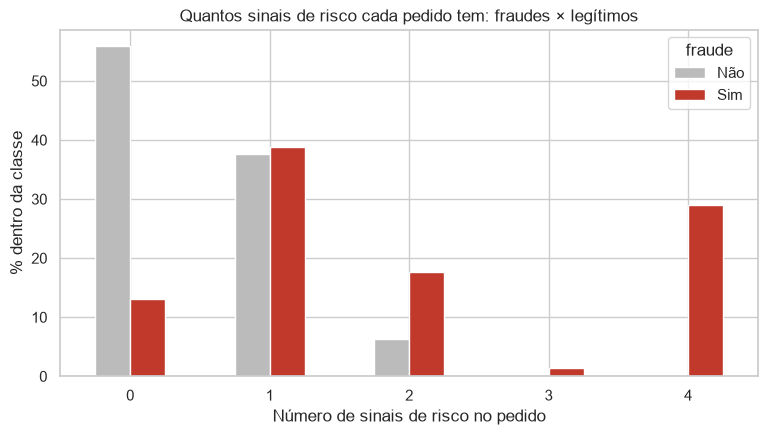

In [45]:
ax = (pd.crosstab(base['n_sinais'], base['fraude'], normalize='columns') * 100).plot.bar(
    color=['#bbbbbb', '#c0392b'], rot=0)
ax.set_title('Quantos sinais de risco cada pedido tem: fraudes × legítimos')
ax.set_xlabel('Número de sinais de risco no pedido'); ax.set_ylabel('% dentro da classe')
plt.show()

> ✍️ **Interpretação da Etapa 6** — *texto do Leandro*
>
> - Para cada hipótese: a evidência é forte, fraca ou inconclusiva? (marcas 🟢 contraste evidente · 🟡 menos conclusivo · 🟣 limitação de mensuração)
> - Quais associações se mantêm nos testes de estratificação (a–e) e quais se enfraquecem?
> - Grupos com taxa alta mas pouca participação nas fraudes: relevantes para o negócio?
> - Qual é o retrato do pedido fraudulento que emerge — e quanto dele também é comum entre clientes legítimos?
>
> _[escrever aqui]_

## Etapa 8 — Priorização e insights

Critérios: **evidência + relevância para o negócio + viabilidade**.
As recomendações são de **investigação**, não intervenções comprovadas.

> ✍️ **Síntese da investigação** — *texto do Leandro*
>
> - Hipóteses com evidência mais consistente.
> - Hipóteses com evidência fraca ou inconclusiva.
> - Limitações dos dados (maturação do rótulo, proxies, base sintética, adversário que se adapta).
> - O que a análise de uma variável por vez não consegue responder.
> - Custo de errar para os dois lados: deixar passar uma fraude × barrar um cliente legítimo.
>
> _[escrever aqui]_

## Conclusões e recomendações para Prevenção a Perdas

> ✍️ **O que as fraudes têm em comum** — *texto do Leandro*
>
> - Resposta direta à pergunta central, em poucas linhas.
>
> _[escrever aqui]_

> ✍️ **Principais fatores associados à fraude** — *texto do Leandro*
>
> - Com os números que sustentam cada um (taxa, n, participação nas fraudes).
>
> _[escrever aqui]_

> ✍️ **Limitações da investigação** — *texto do Leandro*
>
> - O que os dados não permitem afirmar.
>
> _[escrever aqui]_

> ✍️ **Recomendações (até três)** — *texto do Leandro*
>
> - Para cada uma: qual evidência sustenta, e que informação adicional seria necessária.
>
> _[escrever aqui]_

## Reflexão final

> ✍️ **Se eu apresentasse ao diretor de Prevenção a Perdas…** — *texto do Leandro*
>
> - Quais padrões recomendaria investigar primeiro?
> - Quais evidências sustentam essas recomendações?
> - O que a análise de uma variável por vez não permite afirmar?
>
> _[escrever aqui]_